# CivicSense – Batch Prediction

## 1. Introduction

This notebook focuses on using the trained LSTM model with Word2Vec embeddings to classify unseen civic complaints into 12 predefined categories.

The model was selected based on its overall performance during the evaluation phase, achieving 81.92% test accuracy and a 69.77% macro F1-score.

The prediction dataset contains 27,686 complaints that were kept separate from the training, validation, and test datasets.

## 2. Objectives

- Load the trained LSTM model and preprocessing artifacts.
- Load and inspect the unseen civic complaints dataset.
- Convert complaint text into numerical sequences using the saved tokenizer.
- Apply padding using the same sequence length used during training.
- Generate complaint category predictions using the trained model.
- Calculate prediction confidence scores.
- Analyze prediction distribution and confidence levels.
- Export the final predictions while preserving the original complaint information.

In [1]:
# Import libraries for data handling and numerical operations
import os
import pickle
import numpy as np
import pandas as pd

# Import TensorFlow and sequence padding utilities
import tensorflow as tf
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Import visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Set a random seed for reproducibility
np.random.seed(42)
tf.random.set_seed(42)

# Display all columns when inspecting DataFrames
pd.set_option("display.max_columns", None)

print("Libraries imported successfully!")
print("TensorFlow version:", tf.__version__)

Libraries imported successfully!
TensorFlow version: 2.21.0


In [2]:
# Define paths for the trained LSTM model and preprocessing artifacts
model_path = "../models/experiments/lstm_baseline/lstm_baseline_word2vec.keras"
preprocessing_dir = "../models/preprocessing"

# Load the trained LSTM model
lstm_model = load_model(model_path)

# Load the saved tokenizer
with open(os.path.join(preprocessing_dir, "tokenizer.pkl"), "rb") as file:
    tokenizer = pickle.load(file)

# Load the saved label encoder
with open(os.path.join(preprocessing_dir, "label_encoder.pkl"), "rb") as file:
    label_encoder = pickle.load(file)

# Load the maximum sequence length used during training
MAX_LEN = int(np.load(os.path.join(preprocessing_dir, "max_len.npy")))

# Retrieve vocabulary size and number of target categories
VOCAB_SIZE = len(tokenizer.word_index) + 1
NUM_CLASSES = len(label_encoder.classes_)

# Display the loaded artifact information
print("Model and preprocessing artifacts loaded successfully!")
print("Maximum sequence length:", MAX_LEN)
print("Vocabulary size:", VOCAB_SIZE)
print("Number of categories:", NUM_CLASSES)
print("Categories:", label_encoder.classes_)

Model and preprocessing artifacts loaded successfully!
Maximum sequence length: 156
Vocabulary size: 20089
Number of categories: 12
Categories: ['Animal Management' 'Civic Infrastructure and Encroachment'
 'Drainage and Sewerage' 'Electricity and Utilities'
 'Environment and Public Spaces' 'Public Safety' 'Public Sanitation'
 'Road Infrastructure' 'Street Lighting' 'Traffic and Transport'
 'Waste Management' 'Water Supply']


In [3]:
# Define the path to the cleaned prediction dataset
prediction_path = "../data/interim/civicsense_prediction_cleaned.csv"

# Load the unseen complaints dataset
prediction_df = pd.read_csv(prediction_path)

# Display the dataset dimensions
print("Prediction dataset loaded successfully!")
print("Dataset shape:", prediction_df.shape)

# Display the first five records
display(prediction_df.head())

# Check the available columns
print("\nDataset columns:")
print(prediction_df.columns.tolist())

Prediction dataset loaded successfully!
Dataset shape: (27686, 14)


,instruction,issueType,description,location,priority,department,urgency,detectedLanguage,aiConfidence,sentiment,keywords,suggestedResponse,manual_category,cleaned_text
0,"Classify this complaint: ""Sir, we are facing l...",Water Leakage,"Sir, we are facing lot of water problem in 8th...",Opp to seed of truth church,HIGH,Water Supply,high,English,0.9,frustrated,[],Your complaint has been registered with the Wa...,NaN,"Sir, we are facing lot of water problem in 8th..."
1,"Classify this complaint: ""Doddabommasandra Arc...",Garbage Overflow,"Doddabommasandra Arch se Nanjappa Circle, Nanj...",Location not specified,MEDIUM,Sanitation,medium,Hinglish,0.9,neutral,[],Your complaint has been registered with the Sa...,NaN,"Doddabommasandra Arch se Nanjappa Circle, Nanj..."
2,"Classify this complaint: ""Kachra kachra kachra""",Garbage Overflow,Kachra kachra kachra,Sainik Public School Road Dead end 6th Cross...,MEDIUM,Sanitation,medium,Hinglish,0.9,neutral,[],Your complaint has been registered with the Sa...,NaN,Kachra kachra kachra
3,"Classify this complaint: ""Garbage dumped next ...",Garbage Overflow,Garbage dumped next to mysore circle bus stop....,Mysore circle bus stop way to KR Market,HIGH,Sanitation,high,English,0.9,frustrated,[],Your complaint has been registered with the Sa...,NaN,Garbage dumped next to mysore circle bus stop....
4,"Classify this complaint: ""Too many pot holes n...",Pothole,Too many pot holes near GIIS school and petrol...,Near Petrol bunk,HIGH,Road Maintenance,high,English,0.9,frustrated,[],Your complaint has been registered with the Ro...,NaN,Too many pot holes near GIIS school and petrol...



Dataset columns:
['instruction', 'issueType', 'description', 'location', 'priority', 'department', 'urgency', 'detectedLanguage', 'aiConfidence', 'sentiment', 'keywords', 'suggestedResponse', 'manual_category', 'cleaned_text']


In [4]:
# Check missing values in the prediction dataset
print("Missing values in each column:")
display(prediction_df.isnull().sum())

# Check for empty complaint texts
empty_texts = prediction_df["cleaned_text"].isna().sum()

# Check for duplicate complaint texts without removing any records
duplicate_texts = prediction_df["cleaned_text"].duplicated().sum()

# Display basic dataset statistics
print("\nPrediction Dataset Inspection")
print("--------------------------------")
print("Total complaints:", len(prediction_df))
print("Missing complaint texts:", empty_texts)
print("Duplicate complaint texts:", duplicate_texts)

# Display sample complaint texts
print("\nSample complaint texts:")
for i, text in enumerate(prediction_df["cleaned_text"].head(5), start=1):
    print(f"{i}. {text}")

Missing values in each column:


instruction              0
issueType                0
description              0
location                 0
priority                 0
department               0
urgency                  0
detectedLanguage         0
aiConfidence             0
sentiment                0
keywords                 0
suggestedResponse        0
manual_category      27686
cleaned_text             0
dtype: int64


Prediction Dataset Inspection
--------------------------------
Total complaints: 27686
Missing complaint texts: 0
Duplicate complaint texts: 880

Sample complaint texts:
1. Sir, we are facing lot of water problem in 8th main byrappa layout s g palya, c v Raman Nagar Bangalore 93. I have mailed to Mr.Raghu regarding this!! But no response we have approached the bjp office
2. Doddabommasandra Arch se Nanjappa Circle, Nanjappa Circle se Vidyaranyapura First block tak behtar paidal margon ki avashyakta hai, jo is samay uplabdh nahin hain.
3. Kachra kachra kachra
4. Garbage dumped next to mysore circle bus stop. It is very difficult for passengers to stand or sit in bus stop awaiting for bus.
5. Too many pot holes near GIIS school and petrol bunk-Gunjur Fill it as early as possible


In [5]:
# Extract cleaned complaint texts from the prediction dataset
prediction_texts = prediction_df["cleaned_text"].astype(str).tolist()

# Convert complaint texts into numerical sequences using the saved tokenizer
prediction_sequences = tokenizer.texts_to_sequences(prediction_texts)

# Apply the same padding and truncation settings used during training
X_prediction_padded = pad_sequences(
    prediction_sequences,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

# Display the shape and sample sequence information
print("Text tokenization and padding completed!")
print("Total prediction records:", len(prediction_sequences))
print("Padded prediction shape:", X_prediction_padded.shape)
print("Maximum sequence length:", MAX_LEN)

# Display one sample tokenized sequence
print("\nSample padded sequence:")
print(X_prediction_padded[0][:30])

Text tokenization and padding completed!
Total prediction records: 27686
Padded prediction shape: (27686, 156)
Maximum sequence length: 156

Sample padded sequence:
[  105    22    13   263    61     7    27   111     8   507    31     1
    48   612   836   660   704   997  2562    93   150  6446    24    25
     1     4   935 14679   621     9]


In [6]:
# Generate prediction probabilities for all unseen complaints
prediction_probabilities = lstm_model.predict(
    X_prediction_padded,
    batch_size=64,
    verbose=1
)

# Select the category with the highest prediction probability
predicted_class_indices = np.argmax(prediction_probabilities, axis=1)

# Convert numerical predictions into original complaint category names
predicted_categories = label_encoder.inverse_transform(
    predicted_class_indices
)

# Extract the highest probability for each prediction
confidence_scores = np.max(prediction_probabilities, axis=1)

# Display prediction results
print("Batch prediction completed successfully!")
print("Prediction probabilities shape:", prediction_probabilities.shape)
print("Total predictions:", len(predicted_categories))

# Display a few sample predictions
for i in range(5):
    print(f"\nComplaint: {prediction_texts[i]}")
    print(f"Predicted Category: {predicted_categories[i]}")
    print(f"Confidence Score: {confidence_scores[i]:.4f}")

433/433 ━━━━━━━━━━━━━━━━━━━━ 7s 15ms/step
Batch prediction completed successfully!
Prediction probabilities shape: (27686, 12)
Total predictions: 27686

Complaint: Sir, we are facing lot of water problem in 8th main byrappa layout s g palya, c v Raman Nagar Bangalore 93. I have mailed to Mr.Raghu regarding this!! But no response we have approached the bjp office
Predicted Category: Water Supply
Confidence Score: 0.4606

Complaint: Doddabommasandra Arch se Nanjappa Circle, Nanjappa Circle se Vidyaranyapura First block tak behtar paidal margon ki avashyakta hai, jo is samay uplabdh nahin hain.
Predicted Category: Road Infrastructure
Confidence Score: 0.9528

Complaint: Kachra kachra kachra
Predicted Category: Waste Management
Confidence Score: 0.9869

Complaint: Garbage dumped next to mysore circle bus stop. It is very difficult for passengers to stand or sit in bus stop awaiting for bus.
Predicted Category: Waste Management
Confidence Score: 0.9944

Complaint: Too many pot holes near GI

In [7]:
# Create a copy to preserve the original prediction dataset
final_predictions = prediction_df.copy()

# Add the predicted complaint categories
final_predictions["predicted_category"] = predicted_categories

# Add the maximum prediction probability as confidence score
final_predictions["confidence_score"] = confidence_scores

# Assign confidence levels using predefined thresholds
final_predictions["prediction_status"] = np.select(
    [
        final_predictions["confidence_score"] >= 0.80,
        final_predictions["confidence_score"] >= 0.60
    ],
    [
        "High",
        "Medium"
    ],
    default="Low"
)

# Display sample predictions
display(
    final_predictions[
        ["cleaned_text", "predicted_category",
         "confidence_score", "prediction_status"]
    ].head(10)
)

# Verify that all original records are retained
print("Total prediction records:", len(final_predictions))
print("Missing predicted categories:", final_predictions["predicted_category"].isna().sum())

,cleaned_text,predicted_category,confidence_score,prediction_status
0,"Sir, we are facing lot of water problem in 8th...",Water Supply,0.460619,Low
1,"Doddabommasandra Arch se Nanjappa Circle, Nanj...",Road Infrastructure,0.952829,High
2,Kachra kachra kachra,Waste Management,0.986852,High
3,Garbage dumped next to mysore circle bus stop....,Waste Management,0.994388,High
4,Too many pot holes near GIIS school and petrol...,Road Infrastructure,0.970327,High
5,"Akshay Nagar Yelenahalli Bangalore 560068, 9th...",Street Lighting,0.988640,High
6,Ek car 10 dinon se zyada samay se hamare ghar ...,Traffic and Transport,0.839371,High
7,सड़क क्षतिग्रस्त हो रही है।,Road Infrastructure,0.720025,Medium
8,"Namaste ShriMan/Shrimati, kripya is par kuch k...",Waste Management,0.292544,Low
9,No parking leads to traffic jam,Traffic and Transport,0.904089,High


Total prediction records: 27686
Missing predicted categories: 0


In [8]:
# Calculate the number of complaints predicted in each category
category_counts = final_predictions["predicted_category"].value_counts()

# Calculate the percentage distribution of predicted categories
category_percentages = (
    final_predictions["predicted_category"]
    .value_counts(normalize=True) * 100
)

# Combine counts and percentages into one summary table
category_summary = pd.DataFrame({
    "Complaint Count": category_counts,
    "Percentage": category_percentages
})

# Display the category-wise prediction summary
display(category_summary.round(2))

# Verify that all predictions are accounted for
print("Total predicted complaints:", category_summary["Complaint Count"].sum())
print("Number of predicted categories:", len(category_summary))

,Complaint Count,Percentage
predicted_category,,
Road Infrastructure,8765,31.66
Waste Management,7968,28.78
Civic Infrastructure and Encroachment,3016,10.89
Street Lighting,2239,8.09
Traffic and Transport,2153,7.78
Water Supply,1151,4.16
Drainage and Sewerage,1010,3.65
Public Sanitation,803,2.90
Environment and Public Spaces,383,1.38


Total predicted complaints: 27686
Number of predicted categories: 12


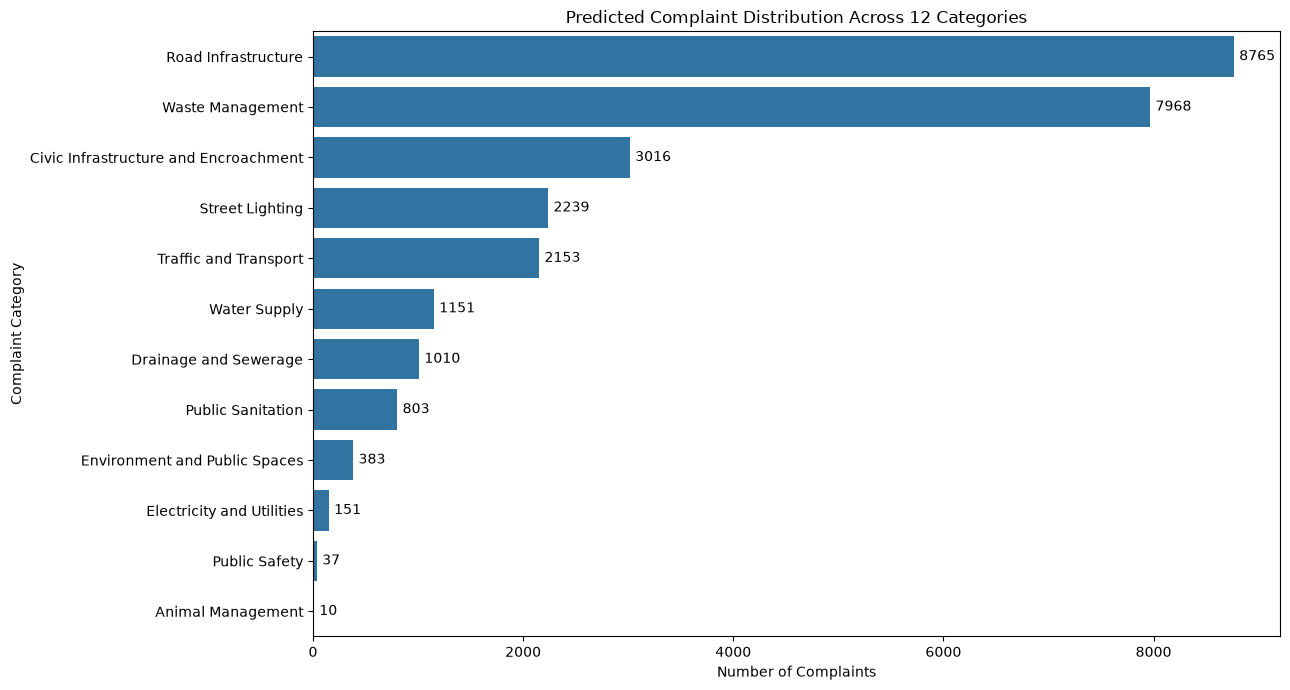

In [9]:
# Plot the predicted complaint count for each category
plt.figure(figsize=(13, 7))

sns.barplot(
    x=category_summary["Complaint Count"],
    y=category_summary.index
)

# Add chart title and axis labels
plt.title("Predicted Complaint Distribution Across 12 Categories")
plt.xlabel("Number of Complaints")
plt.ylabel("Complaint Category")

# Display count labels beside each bar
for index, value in enumerate(category_summary["Complaint Count"]):
    plt.text(value + 50, index, str(value), va="center")

# Adjust layout and display the chart
plt.tight_layout()
plt.show()

In [10]:
# Calculate the count of complaints in each confidence category
confidence_summary = final_predictions["prediction_status"].value_counts()

# Calculate the percentage distribution of confidence categories
confidence_percentage = (
    final_predictions["prediction_status"].value_counts(normalize=True) * 100
)

# Combine counts and percentages into a summary DataFrame
confidence_summary_df = pd.DataFrame({
    "Complaint Count": confidence_summary,
    "Percentage": confidence_percentage
})

# Display the confidence distribution
display(confidence_summary_df.round(2))

# Verify that all predictions are included
print("Total complaints:", confidence_summary_df["Complaint Count"].sum())

,Complaint Count,Percentage
prediction_status,,
High,14765,53.33
Low,9528,34.41
Medium,3393,12.26


Total complaints: 27686


In [11]:
# Create the predictions directory if it does not exist
output_dir = "../data/predictions"
os.makedirs(output_dir, exist_ok=True)

# Save predictions for all 27,686 complaints
final_predictions.to_csv(
    os.path.join(output_dir, "civicsense_batch_predictions.csv"),
    index=False
)

# Extract low-confidence complaints for manual review
low_confidence_df = final_predictions[
    final_predictions["prediction_status"] == "Low"
].copy()

# Save the low-confidence complaints separately
low_confidence_df.to_csv(
    os.path.join(output_dir, "civicsense_low_confidence_review.csv"),
    index=False
)

# Combine category and confidence summaries
prediction_summary = category_summary.join(
    confidence_summary_df,
    how="outer",
    lsuffix="_category",
    rsuffix="_confidence"
)

# Save the prediction summary
prediction_summary.to_csv(
    os.path.join(output_dir, "prediction_summary.csv")
)

# Display saving information
print("All prediction files saved successfully!")
print("------------------------------------------")
print("Total predictions:", len(final_predictions))
print("Low-confidence complaints:", len(low_confidence_df))
print("Output directory:", output_dir)

# Verify the saved files
print("\nSaved files:")
print(os.listdir(output_dir))

All prediction files saved successfully!
------------------------------------------
Total predictions: 27686
Low-confidence complaints: 9528
Output directory: ../data/predictions

Saved files:
['civicsense_batch_predictions.csv', 'civicsense_low_confidence_review.csv', 'prediction_summary.csv']


C:\Users\deepa\AppData\Local\Temp\ipykernel_28984\2064712278.py:23: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  prediction_summary = category_summary.join(


In [12]:
# Create a structured category-wise summary
category_output = category_summary.reset_index()

category_output.columns = [
    "Category",
    "Complaint Count",
    "Percentage"
]

category_output["Summary Type"] = "Category Distribution"

# Create a structured confidence-wise summary
confidence_output = confidence_summary_df.reset_index()

confidence_output.columns = [
    "Confidence Level",
    "Complaint Count",
    "Percentage"
]

confidence_output["Summary Type"] = "Confidence Distribution"

# Standardize columns before combining both summaries
category_output["Category"] = category_output["Category"]
category_output["Confidence Level"] = np.nan

confidence_output["Category"] = np.nan
confidence_output["Confidence Level"] = confidence_output["Confidence Level"]

# Combine both summaries into one structured DataFrame
prediction_summary = pd.concat(
    [
        category_output[
            ["Summary Type", "Category", "Confidence Level",
             "Complaint Count", "Percentage"]
        ],
        confidence_output[
            ["Summary Type", "Category", "Confidence Level",
             "Complaint Count", "Percentage"]
        ]
    ],
    ignore_index=True
)

# Save the corrected summary file
prediction_summary.to_csv(
    os.path.join(output_dir, "prediction_summary.csv"),
    index=False
)

# Display the corrected summary
display(prediction_summary)

print("Prediction summary corrected and saved!")

,Summary Type,Category,Confidence Level,Complaint Count,Percentage
0,Category Distribution,Road Infrastructure,NaN,8765,31.658600
1,Category Distribution,Waste Management,NaN,7968,28.779889
2,Category Distribution,Civic Infrastructure and Encroachment,NaN,3016,10.893592
3,Category Distribution,Street Lighting,NaN,2239,8.087120
4,Category Distribution,Traffic and Transport,NaN,2153,7.776494
5,Category Distribution,Water Supply,NaN,1151,4.157336
6,Category Distribution,Drainage and Sewerage,NaN,1010,3.648053
7,Category Distribution,Public Sanitation,NaN,803,2.900383
8,Category Distribution,Environment and Public Spaces,NaN,383,1.383371
9,Category Distribution,Electricity and Utilities,NaN,151,0.545402


Prediction summary corrected and saved!
